# 🛡️ AnomalyGuard — Transaction Anomaly Detection & Analysis
**Stack & Scale | Remote Internship 2026 — AI Engineering Week 03**
**Author:** AI Engineering Intern
**Domain:** Financial Technology & Transaction Monitoring

---

### Real-World Challenge
Financial and operational risk teams face immense volumes of daily payment transactions. To prevent alert fatigue and maintain audit integrity, organizations require a reproducible unsupervised learning pipeline to rank and highlight unusual records.

> **CRITICAL OPERATIONAL PRINCIPLE**:
> An anomaly is an analytical **review signal**, not proof of fraud. Unsupervised anomaly detection surfaces statistical rarities for operational triage or stepped-up authentication; it never establishes criminal or malicious intent on its own.


## 📅 Monday: Dataset Exploration and Problem Definition
**Objectives:**
- Load transaction dataset with clear provenance and schema.
- Inspect missing values, data types, and statistical distributions.
- Quantify right-skewed transaction amounts and define review objective.


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure src modules can be imported
sys.path.append(os.path.abspath('..'))

from src.eda import compute_dataset_summary, get_numeric_distribution_stats, compute_correlation_matrix
from src.preprocessing import TransactionPreprocessor
from src.baseline import RuleBasedStatisticalBaseline
from src.models import IsolationForestDetector, LocalOutlierFactorDetector, evaluate_seed_stability
from src.evaluation import evaluate_threshold_sensitivity, compute_comprehensive_metrics, explain_top_anomalies

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Environment loaded successfully.")

Environment loaded successfully.


In [2]:
# Load transaction dataset
data_path = '../data/transactions.csv'
df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} transactions, {df.shape[1]} features.")
df.head()

Dataset Shape: 10000 transactions, 14 features.


,transaction_id,timestamp,customer_id,merchant_category,channel,amount,distance_from_home_km,distance_from_last_txn_km,time_since_last_txn_hours,device_risk_score,failed_attempts_last_24h,is_international,is_synthetic_anomaly,anomaly_scenario
0,TXN_000001,2026-10-01 00:00:30,CUST_2206,transport,atm,14.38,7.06,3.27,20.76,0.105,0,0,0,normal
1,TXN_000002,2026-10-01 00:01:19,CUST_1863,entertainment,mobile_app,39.36,4.73,4.21,22.39,0.144,0,0,0,normal
2,TXN_000003,2026-10-01 00:02:16,CUST_1547,utilities,atm,235.70,5.89,18.78,0.39,0.095,0,0,0,normal
3,TXN_000004,2026-10-01 00:05:49,CUST_2060,grocery,pos_contactless,53.78,0.10,4.57,51.50,0.037,0,0,0,normal
4,TXN_000005,2026-10-01 00:09:48,CUST_2007,utilities,web,36.05,2.13,2.92,8.13,0.022,0,0,0,normal


In [3]:
# Dataset Summary and Missing Value Inspection
summary = compute_dataset_summary(df)
print(f"Total Rows: {summary['n_rows']}")
print(f"Total Missing Values: {summary['total_missing_values']}")
print(f"Numerical Columns: {summary['numeric_columns']}")
print(f"Categorical Columns: {summary['categorical_columns']}")

# Distribution Statistics
dist_stats = get_numeric_distribution_stats(df)
dist_stats

Total Rows: 10000
Total Missing Values: 0
Numerical Columns: ['amount', 'distance_from_home_km', 'distance_from_last_txn_km', 'time_since_last_txn_hours', 'device_risk_score', 'failed_attempts_last_24h', 'is_international', 'is_synthetic_anomaly']
Categorical Columns: ['transaction_id', 'timestamp', 'customer_id', 'merchant_category', 'channel', 'anomaly_scenario']


,Feature,Count,Mean,Std,Median,IQR,Min,Max,Skewness
0,amount,10000,117.294918,564.441172,44.995,47.3525,0.55,9496.190,11.297110
1,distance_from_home_km,10000,20.651008,198.032569,6.720,7.0400,0.03,4990.340,19.051439
2,distance_from_last_txn_km,10000,16.012316,194.109610,3.540,4.4925,0.00,4488.510,17.861804
3,time_since_last_txn_hours,10000,18.101543,18.353577,12.365,19.7000,0.01,163.640,2.039153
4,device_risk_score,10000,0.125838,0.130331,0.094,0.1110,0.00,0.983,3.468614
5,failed_attempts_last_24h,10000,0.096800,0.425262,0.000,0.0000,0.00,5.000,6.128401
6,is_international,10000,0.037500,0.189993,0.000,0.0000,0.00,1.000,4.869573


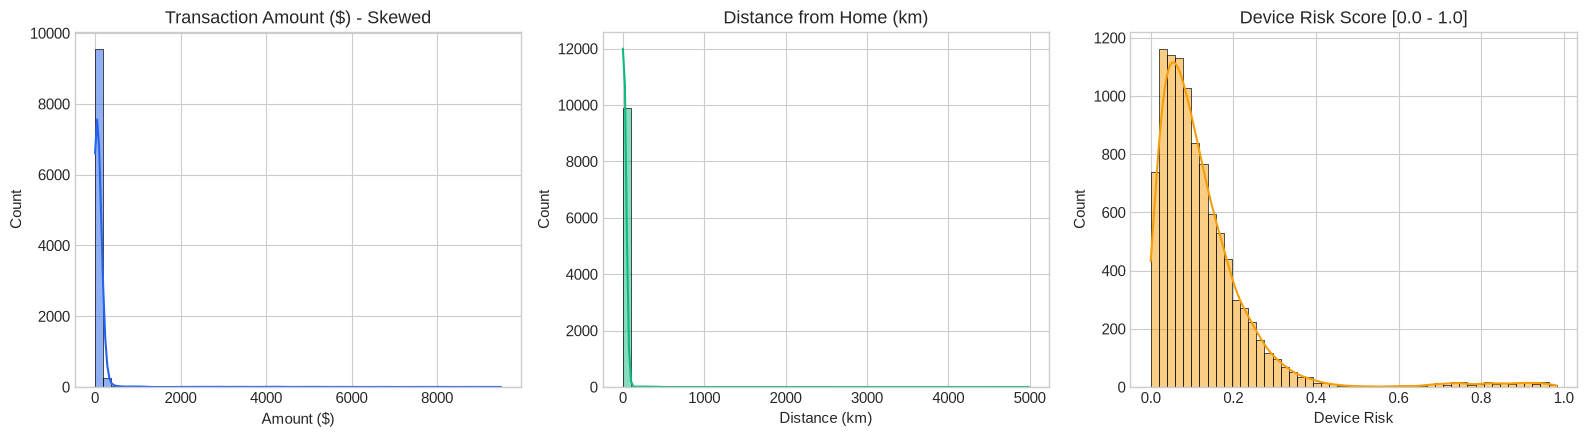

In [4]:
# Visualize Distribution of Key Signals
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(df['amount'], bins=50, kde=True, ax=axes[0], color='#2563EB')
axes[0].set_title('Transaction Amount ($) - Skewed')
axes[0].set_xlabel('Amount ($)')

sns.histplot(df['distance_from_home_km'], bins=50, kde=True, ax=axes[1], color='#10B981')
axes[1].set_title('Distance from Home (km)')
axes[1].set_xlabel('Distance (km)')

sns.histplot(df['device_risk_score'], bins=50, kde=True, ax=axes[2], color='#F59E0B')
axes[2].set_title('Device Risk Score [0.0 - 1.0]')
axes[2].set_xlabel('Device Risk')

plt.tight_layout()
os.makedirs('../figures', exist_ok=True)
plt.savefig('../figures/eda_distributions.png', dpi=200)
plt.show()

## 📅 Tuesday: Preprocessing, Feature Engineering & Baseline Benchmark
**Objectives:**
- Handle missing values and categorical features without evaluation leakage.
- Synthesize domain behavioral signals:
  - **Travel Velocity ($\Delta d / \Delta t$)**: Highlights physically impossible geographic travel (>800 km/h).
  - **Log-amount transform**: Mitigates heavy right skewness.
  - **Risk interaction term**: Multiplies device risk by authentication failure count.
- Scale numeric features using `RobustScaler` (median & IQR based to avoid outlier distortion).
- Construct a transparent **Statistical and Rule-Based Baseline** as an operational benchmark.


In [5]:
# Initialize and fit Preprocessor
preprocessor = TransactionPreprocessor(use_log_transforms=True, scale_features=True)
X_scaled, feat_df = preprocessor.fit_transform(df)

print(f"Original Feature Count: {df.shape[1]}")
print(f"Processed Feature Matrix Shape: {X_scaled.shape}")
print("Engineered Feature Names:", preprocessor.feature_names_[:8], "...")

Original Feature Count: 14
Processed Feature Matrix Shape: (10000, 27)
Engineered Feature Names: ['amount', 'log_amount', 'distance_from_home_km', 'log_dist_home', 'distance_from_last_txn_km', 'time_since_last_txn_hours', 'travel_velocity_kmh', 'log_velocity'] ...


In [6]:
# Define and Execute Tuesday's Rule-Based Baseline Benchmark
baseline = RuleBasedStatisticalBaseline(z_score_threshold=3.0, velocity_cutoff_kmh=800.0)
baseline_scores, baseline_flags, rule_triggers = baseline.predict_scores_and_flags(df)

print(f"Baseline Rules Flagged: {baseline_flags.sum()} records ({(baseline_flags.sum()/len(df))*100:.2f}%)")
print("\nRule Trigger Counts:")
print(rule_triggers.sum())

Baseline Rules Flagged: 389 records (3.89%)

Rule Trigger Counts:
rule_impossible_travel     39
rule_extreme_amount       350
rule_credential_risk       81
rule_suspicious_intl       58
dtype: int64


## 📅 Wednesday: Isolation Forest Anomaly Detection
**Objectives:**
- Train an unsupervised `IsolationForest` with documented hyper-parameters and fixed random seed.
- Generate decision function and normalize to calibrated anomaly scores $\in [0, 1]$.
- Rank most anomalous transactions and inspect feature deviations.


In [7]:
# Configure and Train Isolation Forest
CONTAMINATION_RATE = 0.025  # Expected anomaly frequency (2.5%)
RANDOM_SEED = 42

iso_forest = IsolationForestDetector(
    n_estimators=150,
    contamination=CONTAMINATION_RATE,
    max_samples='auto',
    random_state=RANDOM_SEED
)

# Fit strictly on feature matrix (NO ground-truth label input!)
iso_forest.fit(X_scaled)

iso_scores = iso_forest.predict_anomaly_scores(X_scaled)
iso_flags = iso_forest.predict_flags(X_scaled)

print(f"Isolation Forest Flagged: {iso_flags.sum()} transactions for review.")

Isolation Forest Flagged: 250 transactions for review.


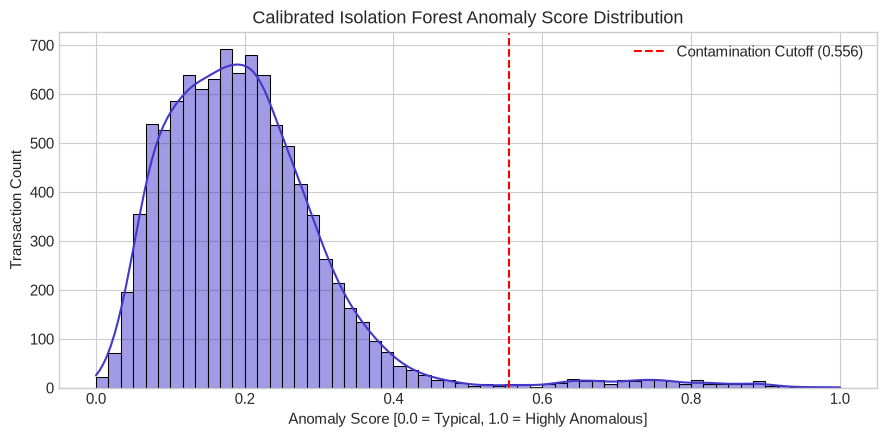

In [8]:
# Score Distribution Plot
plt.figure(figsize=(9, 4.5))
sns.histplot(iso_scores, bins=60, kde=True, color='#4338CA')
threshold_val = np.percentile(iso_scores, (1 - CONTAMINATION_RATE) * 100)
plt.axvline(threshold_val, color='red', linestyle='--', label=f'Contamination Cutoff ({threshold_val:.3f})')
plt.title('Calibrated Isolation Forest Anomaly Score Distribution')
plt.xlabel('Anomaly Score [0.0 = Typical, 1.0 = Highly Anomalous]')
plt.ylabel('Transaction Count')
plt.legend()
plt.tight_layout()
plt.savefig('../figures/isolation_forest_scores.png', dpi=200)
plt.show()

In [9]:
# Inspect Top 10 Anomalies with Human-Interpretable Review Drivers
top_anomalies = explain_top_anomalies(df, iso_scores, iso_flags, top_k=10)
top_anomalies[['Rank', 'Anomaly_Score', 'Transaction_ID', 'Amount', 'Category', 'Key_Review_Drivers']]

,Rank,Anomaly_Score,Transaction_ID,Amount,Category,Key_Review_Drivers
0,1,1.0000,TXN_004747,110.30,grocery,distance_from_home_km elevated (3965.5 vs med ...
1,2,0.9880,TXN_007793,43.65,luxury_retail,distance_from_home_km elevated (3064.0 vs med ...
2,3,0.9806,TXN_008717,83.49,grocery,distance_from_home_km elevated (1902.7 vs med ...
3,4,0.9781,TXN_003045,965.36,transport,amount elevated (965.4 vs med 45.0); distance_...
4,5,0.9615,TXN_008795,13.47,grocery,distance_from_home_km elevated (4523.7 vs med ...
5,6,0.9487,TXN_001713,30.83,transport,distance_from_home_km elevated (4410.7 vs med ...
6,7,0.9356,TXN_002798,93.65,entertainment,distance_from_home_km elevated (4525.0 vs med ...
7,8,0.9331,TXN_004126,5028.49,luxury_retail,amount elevated (5028.5 vs med 45.0); device_r...
8,9,0.9204,TXN_000068,204.01,utilities,amount elevated (204.0 vs med 45.0); distance_...
9,10,0.9171,TXN_004492,26.15,transport,distance_from_home_km elevated (1447.3 vs med ...


## 📅 Thursday: Threshold Sensitivity & Evaluation
**Objectives:**
- Evaluate threshold sensitivity: analyze flag counts across contamination percentiles.
- Quantify operational trade-offs: Precision vs Recall, review capacity vs detection coverage.
- If trustworthy evaluation labels exist, calculate F1, PR-AUC, and ROC-AUC.


In [10]:
# Threshold Sensitivity Analysis
y_eval = df['is_synthetic_anomaly'].values if 'is_synthetic_anomaly' in df.columns else None

sensitivity_table = evaluate_threshold_sensitivity(
    anomaly_scores=iso_scores,
    ground_truth=y_eval,
    percentile_thresholds=[85.0, 90.0, 95.0, 97.0, 97.5, 98.0, 99.0, 99.5]
)
sensitivity_table

,Percentile_Cutoff,Score_Threshold,Flagged_Count,Flag_Rate_%,Precision,Recall,F1_Score,TP,FP,FN,TN
0,85.0,0.2934,1500,15.0,0.1667,1.000,0.2857,250,1250,0,8500
1,90.0,0.3243,1000,10.0,0.2500,1.000,0.4000,250,750,0,9000
2,95.0,0.3821,500,5.0,0.5000,1.000,0.6667,250,250,0,9500
3,97.0,0.4573,300,3.0,0.8333,1.000,0.9091,250,50,0,9700
4,97.5,0.5559,250,2.5,0.9800,0.980,0.9800,245,5,5,9745
5,98.0,0.6476,200,2.0,0.9950,0.796,0.8844,199,1,51,9749
6,99.0,0.7629,100,1.0,1.0000,0.400,0.5714,100,0,150,9750
7,99.5,0.8321,50,0.5,1.0000,0.200,0.3333,50,0,200,9750


In [11]:
# Comparative Model Metrics
iso_metrics = compute_comprehensive_metrics(iso_scores, iso_flags, y_eval, "Isolation Forest")
baseline_metrics = compute_comprehensive_metrics(baseline_scores, baseline_flags, y_eval, "Rule-Based Baseline")

benchmark_df = pd.DataFrame([baseline_metrics, iso_metrics])
benchmark_df

,Model,ROC_AUC,PR_AUC,Precision,Recall,F1_Score,TP,FP,FN,TN,Flagged_Total
0,Rule-Based Baseline,0.9945,0.8569,0.5193,0.808,0.6322,202,187,48,9563,389
1,Isolation Forest,0.9999,0.9963,0.9800,0.980,0.9800,245,5,5,9745,250


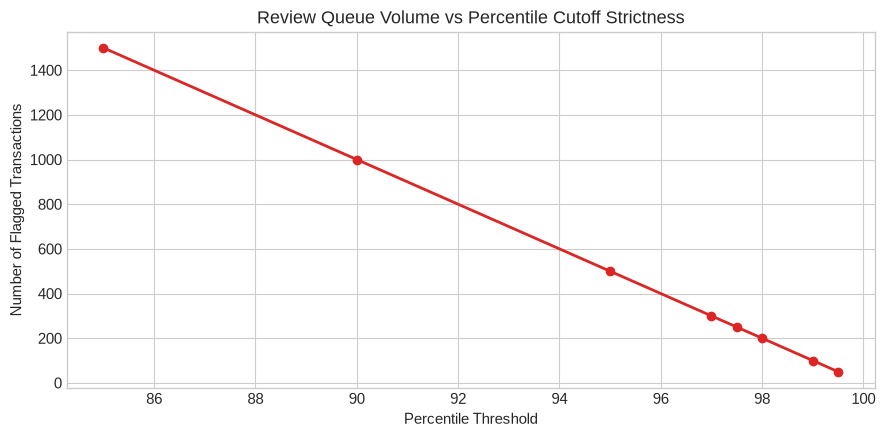

In [12]:
# Review Queue vs Threshold Visualization
plt.figure(figsize=(9, 4.5))
plt.plot(sensitivity_table['Percentile_Cutoff'], sensitivity_table['Flagged_Count'], marker='o', color='#DC2626', linewidth=2)
plt.title('Review Queue Volume vs Percentile Cutoff Strictness')
plt.xlabel('Percentile Threshold')
plt.ylabel('Number of Flagged Transactions')
plt.grid(True)
plt.tight_layout()
plt.savefig('../figures/threshold_sensitivity.png', dpi=200)
plt.show()

## 🔬 Optional Stretch Challenges
1. **Local Outlier Factor (LOF) Comparison & Prediction Semantics**:
   - Compares local neighbor density vs global recursive partition.
2. **Random Seed Stability**:
   - Assesses rank stability across arbitrary initialization seeds using Spearman rank correlation.


In [13]:
# 1. Local Outlier Factor (LOF)
lof = LocalOutlierFactorDetector(n_neighbors=25, contamination=CONTAMINATION_RATE)
lof.fit(X_scaled)
lof_scores = lof.predict_anomaly_scores(X_scaled)
lof_flags = lof.predict_flags(X_scaled)

lof_metrics = compute_comprehensive_metrics(lof_scores, lof_flags, y_eval, "Local Outlier Factor (LOF)")
stretch_benchmark = pd.DataFrame([baseline_metrics, iso_metrics, lof_metrics])
stretch_benchmark

,Model,ROC_AUC,PR_AUC,Precision,Recall,F1_Score,TP,FP,FN,TN,Flagged_Total
0,Rule-Based Baseline,0.9945,0.8569,0.5193,0.808,0.6322,202,187,48,9563,389
1,Isolation Forest,0.9999,0.9963,0.9800,0.980,0.9800,245,5,5,9745,250
2,Local Outlier Factor (LOF),0.5019,0.2054,0.2511,0.224,0.2368,56,167,194,9583,223


In [14]:
# 2. Random Seed Stability Analysis
stability_result = evaluate_seed_stability(X_scaled[:2000], seeds=[42, 101, 777, 2026], n_estimators=100)
print(f"Mean Spearman Rank Correlation across seeds: {stability_result['mean_spearman_rho']:.4f}")
print(f"Highly Stable (>0.90): {stability_result['is_highly_stable']}")
stability_result['pairwise_correlations']

Mean Spearman Rank Correlation across seeds: 0.9342
Highly Stable (>0.90): True


,Seed_A,Seed_B,Spearman_Rho
0,42,101,0.931135
1,42,777,0.933514
2,42,2026,0.925635
3,101,777,0.941636
4,101,2026,0.924909
5,777,2026,0.948277


## 📅 Friday: Practical Findings, False-Positive Risk & Limitations
### Why False Positives Occur in Unsupervised Anomaly Detection
1. **Legitimate High-Value Purchases**: High-net-worth customers purchasing luxury goods, electronics, or booking travel fall in the extreme right tail of amounts.
2. **Vacation & Commuting**: Fast legitimate transit or connecting flights cause geographic displacement spikes.
3. **New Device Onboarding**: Switching phones or using private browsing elevates device risk scores without fraud.

### Operational Recommendations
- **Tiered Triage**: Route top 1% to automated 2FA challenges (SMS/App prompt) rather than card declines.
- **Explainability**: Always surface key feature deviation notes to review analysts to prevent audit fatigue.
- **Model Audits**: Continuously re-calibrate contamination rates based on staffing capacity.
